In [1]:
import sys
sys.path.append('..')
import torch
import cying.nn as cynn
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def bytes_to_unicode():
    bs = (
        list(range(ord("!"), ord("~") + 1)) +
        list(range(ord("¡"), ord("¬") + 1)) +
        list(range(ord("®"), ord("ÿ") + 1))
    )
    
    cs = bs.copy()
    n = 0
    
    for b in range(2**8):
        if b not in bs:
            bs.append(b)
            cs.append(2**8 + n)
            n += 1

    cs = [chr(code) for code in cs]
    
    return dict(zip(bs, cs))

def get_reverse_mapping(forward_map):
    return {v: k for k, v in forward_map.items()}

forward_map = bytes_to_unicode()
reverse_map = get_reverse_mapping(forward_map)
from tokenizers import Tokenizer
tokenizer = Tokenizer.from_file("./cci3_tokenizer.json")
def unicode_str_to_bytes(unicode_str):
    return bytes([reverse_map[c] for c in unicode_str])

In [3]:
device = torch.device('cuda:0')
opt_lang_model = torch.load('./models/model0.pth',map_location=device,weights_only=False)

In [4]:
token_seq = '曾巩:为人廉洁奉公,才华横溢,关心民间疾苦曾巩,字子固,是我国北宋时'
token_seq_encode = torch.tensor(tokenizer.encode(token_seq).ids)[None,:]
word = []
while True:
    word.append(opt_lang_model(
        token_seq_encode.to(device),
        causal_mask=torch.triu(torch.ones(token_seq_encode.shape[1], token_seq_encode.shape[1]), diagonal=1).bool().to(device)
    )[0,-1].argmax().cpu())
    if word[-1] == 3:
        break
    else:
        token_seq_encode = torch.cat([token_seq_encode,word[-1][None,None]],dim=1)
        unicode_word = tokenizer.decode(word)
        print(unicode_word, end='')

,,是,是古代,是古代,,是古代,是,是古代,是古代,是古代,是古代,,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,是古代,

KeyboardInterrupt: 

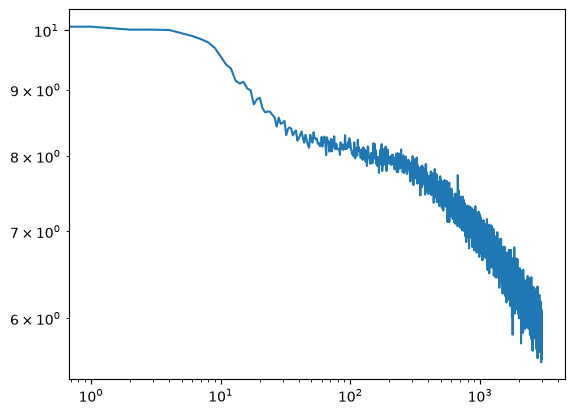

In [5]:
loss_values = torch.load('./loss_values/loss_values_0.pth').cpu()
plt.plot(range(loss_values.size(0)),loss_values)
plt.yscale('log')
plt.xscale('log')